In [3]:
# Import libraries for data handling, visualization, text processing, and machine learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import re
import string

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)


In [5]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate messages:")
print(df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print(df["label"].value_counts(normalize=True) * 100)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None

Missing values:
label      0
message    0
dtype: int64

Duplicate messages:
403

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [6]:
# Remove duplicate messages
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)
print("\nRemaining duplicates:", df.duplicated().sum())

Duplicates removed successfully!
New dataset shape: (5169, 2)

Remaining duplicates: 0


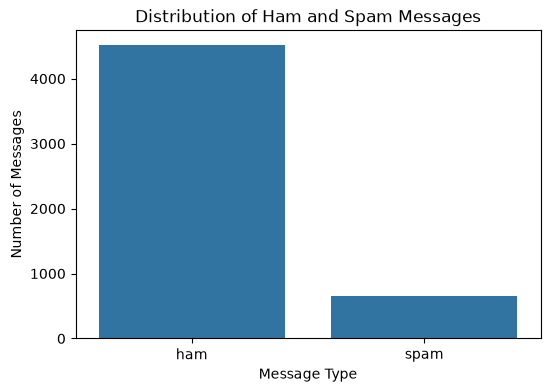

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="label")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [8]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["clean_message"] = df["message"].apply(clean_text)

print("Text preprocessing completed!")
print(df[["message", "clean_message"]].head(10))

Text preprocessing completed!
                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   
5  FreeMsg Hey there darling it's been 3 week's n...   
6  Even my brother is not like to speak with me. ...   
7  As per your request 'Melle Melle (Oru Minnamin...   
8  WINNER!! As a valued network customer you have...   
9  Had your mobile 11 months or more? U R entitle...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in a wkly comp to win fa cup final ...  
3        u dun say so early hor u c already then say  
4  nah i dont think he goes to usf he lives aroun...  
5  freemsg hey there da

In [9]:
# Convert SMS text into numerical features
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)

X = tfidf.fit_transform(df["clean_message"])
y = df["label"].map({"ham": 0, "spam": 1})

print("TF-IDF vectorization completed!")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of unique features:", len(tfidf.get_feature_names_out()))

TF-IDF vectorization completed!
Feature matrix shape: (5169, 5000)
Target shape: (5169,)
Number of unique features: 5000


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training and testing split completed!
Training samples: 4135
Testing samples: 1034


In [11]:
# Initialize the models
nb_model = MultinomialNB()
lr_model = LogisticRegression(max_iter=1000)

# Train the Naive Bayes model
nb_model.fit(X_train, y_train)

# Train the Logistic Regression model
lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [12]:
# Generate predictions
nb_pred = nb_model.predict(X_test)
lr_pred = lr_model.predict(X_test)

# Evaluate Naive Bayes
print("MULTINOMIAL NAIVE BAYES")
print("Accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred), 4))
print("Recall:", round(recall_score(y_test, nb_pred), 4))
print("F1-score:", round(f1_score(y_test, nb_pred), 4))

print("\nLOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(y_test, lr_pred), 4))
print("Recall:", round(recall_score(y_test, lr_pred), 4))
print("F1-score:", round(f1_score(y_test, lr_pred), 4))

MULTINOMIAL NAIVE BAYES
Accuracy: 0.972
Precision: 1.0
Recall: 0.7786
F1-score: 0.8755

LOGISTIC REGRESSION
Accuracy: 0.9468
Precision: 0.9872
Recall: 0.5878
F1-score: 0.7368


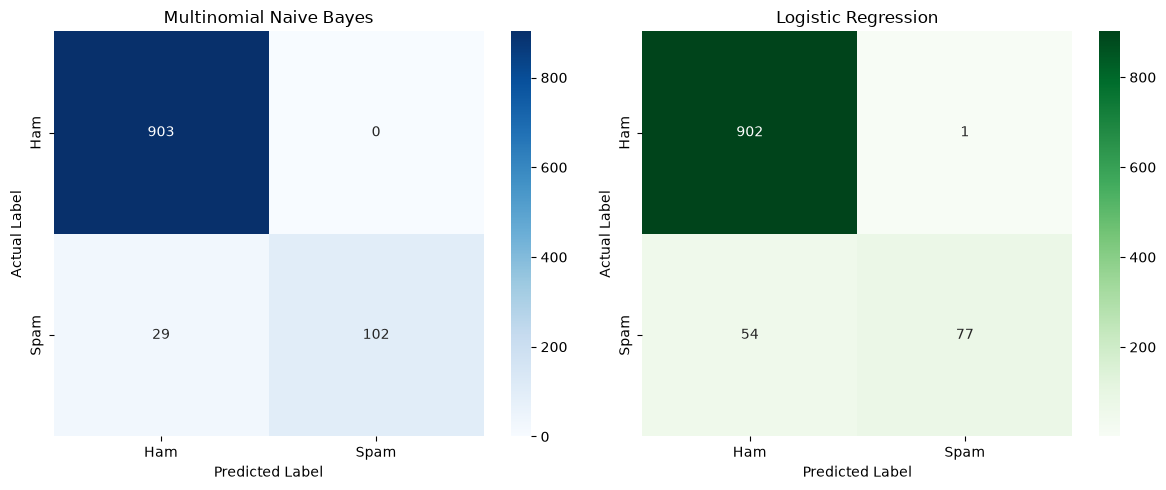

In [13]:
# Create confusion matrices
nb_cm = confusion_matrix(y_test, nb_pred)
lr_cm = confusion_matrix(y_test, lr_pred)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    nb_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"], ax=axes[0]
)
axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    lr_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"], ax=axes[1]
)
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [14]:
print("MULTINOMIAL NAIVE BAYES")
print(classification_report(
    y_test,
    nb_pred,
    target_names=["Ham", "Spam"]
))

print("\nLOGISTIC REGRESSION")
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Ham", "Spam"]
))

MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       1.00      0.78      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034


LOGISTIC REGRESSION
              precision    recall  f1-score   support

         Ham       0.94      1.00      0.97       903
        Spam       0.99      0.59      0.74       131

    accuracy                           0.95      1034
   macro avg       0.97      0.79      0.85      1034
weighted avg       0.95      0.95      0.94      1034



In [15]:
def predict_sms(message):
    cleaned_message = clean_text(message)
    message_vector = tfidf.transform([cleaned_message])
    prediction = nb_model.predict(message_vector)[0]

    if prediction == 1:
        return "Spam"
    else:
        return "Ham (Legitimate)"


print(predict_sms("Congratulations! You have won a free prize. Call now!"))
print(predict_sms("Hey, are we meeting for lunch today?"))

Spam
Ham (Legitimate)


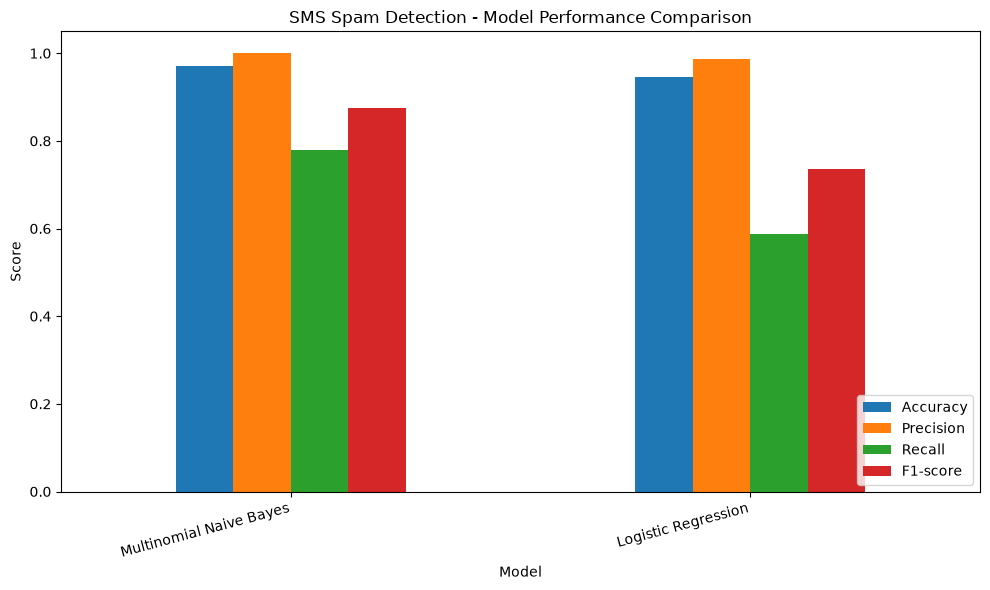

                     Model  Accuracy  Precision  Recall  F1-score
0  Multinomial Naive Bayes    0.9720     1.0000  0.7786    0.8755
1      Logistic Regression    0.9468     0.9872  0.5878    0.7368


In [16]:
results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, lr_pred)
    ],
    "Precision": [
        precision_score(y_test, nb_pred),
        precision_score(y_test, lr_pred)
    ],
    "Recall": [
        recall_score(y_test, nb_pred),
        recall_score(y_test, lr_pred)
    ],
    "F1-score": [
        f1_score(y_test, nb_pred),
        f1_score(y_test, lr_pred)
    ]
})

results.set_index("Model").plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1.05)
)

plt.title("SMS Spam Detection - Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(results.round(4))

In [17]:
import pickle

with open("sms_spam_model.pkl", "wb") as file:
    pickle.dump(nb_model, file)

with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [18]:
import os

print("Model file exists:", os.path.exists("sms_spam_model.pkl"))
print("Vectorizer file exists:", os.path.exists("tfidf_vectorizer.pkl"))

Model file exists: True
Vectorizer file exists: True


In [19]:
import pickle

# Load the saved model and vectorizer
with open("sms_spam_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("tfidf_vectorizer.pkl", "rb") as file:
    loaded_tfidf = pickle.load(file)

# Test the loaded model
test_message = "Congratulations! You have won a free prize. Call now!"

cleaned_message = clean_text(test_message)
message_vector = loaded_tfidf.transform([cleaned_message])
prediction = loaded_model.predict(message_vector)[0]

print("Test message:", test_message)
print("Prediction:", "Spam" if prediction == 1 else "Ham (Legitimate)")
print("Saved model works successfully!")

Test message: Congratulations! You have won a free prize. Call now!
Prediction: Spam
Saved model works successfully!
